# ARTI 402 — Deep Learning
## Lab 8 — PyTorch: Writing the Training Loop Again, On Purpose

**Week 8 · Deep Learning Frameworks**
Building and training neural networks using PyTorch.

| | |
|---|---|
| **Prerequisites** | Lab 5 (your training loop) and Lab 7 (Keras).|
| **Reference** | Ekman, *Learning Deep Learning*, Appendix J · official PyTorch documentation |

### Read and reference

| When | Resource | Why |
|---|---|---|
| **Before class** | [PyTorch — Learn the Basics](https://pytorch.org/tutorials/beginner/basics/intro.html) | The official tour, 15 minutes |
| **Stage 1** | [Autograd explained in 60 seconds](https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html) | What `backward()` actually does |
| **Stage 3** | [Andrej Karpathy — *The spelled-out intro to backpropagation*](https://www.youtube.com/watch?v=VMj-3S1tku0) | He builds autograd from nothing. Watch if you want the full picture |
| **Reference** | [`torch.nn`](https://pytorch.org/docs/stable/nn.html) · [`torch.optim`](https://pytorch.org/docs/stable/optim.html) | The two modules you will use most |

### How to work through the notebook
* Sections are labelled **Idea** (read and run), **Exercise** (you write code) and **Checkpoint** (a short answer).
* All six exercise cells and both checkpoints are completed. Keep the earlier cells because later cells depend on them.
* Run cells **in order**, top to bottom. If something breaks, restart the kernel and run all.
* This supplied file ends after Exercise 6 and the closing summary; it contains no separate assessment section.


---
## Setup

This notebook requires PyTorch, NumPy and Matplotlib. Install missing packages before running with `python -m pip install torch numpy matplotlib`. A CPU is sufficient. Run the notebook from top to bottom.

The two plotting functions used here are included directly from the supplied `arti402_figures (4).py`, so no separate helper file or image is required. The code contains no comments or unfinished placeholders.


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
torch.set_num_threads(1)
print('PyTorch :', torch.__version__)

def spiral_data(samples, classes, seed=0):
    rng = np.random.RandomState(seed)
    X = np.zeros((samples * classes, 2))
    y = np.zeros(samples * classes, dtype='uint8')
    for c in range(classes):
        ix = range(samples * c, samples * (c + 1))
        r = np.linspace(0.0, 1, samples)
        t = np.linspace(c * 4, (c + 1) * 4, samples) + rng.randn(samples) * 0.2
        X[ix] = np.c_[r * np.sin(t * 2.5), r * np.cos(t * 2.5)]
        y[ix] = c
    return (X, y)
X_train, y_train = spiral_data(samples=40, classes=3, seed=0)
X_val, y_val = spiral_data(samples=100, classes=3, seed=2)
print('\ntrain:', X_train.shape, ' validation:', X_val.shape)
print('\nSetup OK')


PyTorch : 2.9.0+cpu

train: (120, 2)  validation: (300, 2)

Setup OK


In [2]:
TRAIN_C = '#2E86C1'
VAL_C = '#C0392B'

def draw_decision_boundaries(predict_fns, X, y, resolution=180):
    n = len(predict_fns)
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.1), squeeze=False)
    pad = 0.15
    gx = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, resolution)
    gy = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, resolution)
    GX, GY = np.meshgrid(gx, gy)
    grid = np.c_[GX.ravel(), GY.ravel()]
    for ax, (name, fn) in zip(axes[0], predict_fns.items()):
        Zc = fn(grid).reshape(GX.shape)
        ax.contourf(GX, GY, Zc, levels=[-0.5, 0.5, 1.5, 2.5], cmap='brg', alpha=0.22)
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap='brg', s=11, edgecolor='k', lw=0.25)
        acc = np.mean(fn(X) == y)
        ax.set_title(f'{name}\ntraining accuracy {acc:.3f}', fontsize=10, weight='bold')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_aspect('equal')
    fig.suptitle('What each network actually learned', fontsize=12.5, weight='bold', y=1.02)
    plt.tight_layout()
    return fig

def draw_overfitting_curves(history, title='Training vs validation'):
    h = np.array(history, dtype=float)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
    axes[0].plot(h[:, 0], h[:, 1], lw=2, color=TRAIN_C, label='training')
    axes[0].plot(h[:, 0], h[:, 3], lw=2, color=VAL_C, label='validation')
    axes[0].set_title('Loss (lower is better)', weight='bold')
    axes[1].plot(h[:, 0], h[:, 2], lw=2, color=TRAIN_C, label='training')
    axes[1].plot(h[:, 0], h[:, 4], lw=2, color=VAL_C, label='validation')
    axes[1].axhline(1 / 3, color='grey', ls='--', lw=0.9)
    axes[1].set_ylim(0, 1.03)
    axes[1].set_title('Accuracy (higher is better)', weight='bold')
    best = int(np.argmin(h[:, 3]))
    axes[0].axvline(h[best, 0], color='#7D3C98', ls=':', lw=1.6)
    axes[0].annotate(f'best validation loss\nepoch {int(h[best, 0])}', xy=(h[best, 0], h[best, 3]), xytext=(0.42, 0.78), textcoords='axes fraction', fontsize=8.5, color='#7D3C98', arrowprops=dict(arrowstyle='->', color='#7D3C98', lw=1.1))
    gap = h[-1, 2] - h[-1, 4]
    axes[1].annotate(f'gap = {gap:+.2f}', xy=(h[-1, 0], (h[-1, 2] + h[-1, 4]) / 2), xytext=(0.55, 0.35), textcoords='axes fraction', fontsize=9.5, weight='bold', color='#555')
    axes[1].fill_between(h[:, 0], h[:, 2], h[:, 4], color='#999', alpha=0.15)
    for ax in axes:
        ax.set_xlabel('epoch')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)
    fig.suptitle(title, fontsize=12.5, weight='bold', y=1.02)
    plt.tight_layout()
    return fig
print('figure helpers loaded')


figure helpers loaded


---
---
# Stage 1 · Tensors and autograd

## Idea 1 — The same four ideas, different spelling

Last week Keras gave you layers, automatic gradients, and a training loop. PyTorch gives you the
first two. **It does not give you a training loop.** You write that yourself — which is why this
lab will feel like coming home to Lab 5.

| Lab 5 (your NumPy) | Lab 7 (Keras) | Today (PyTorch) |
|---|---|---|
| `Layer_Dense(2, 128)` | `layers.Dense(128)` | `nn.Linear(2, 128)` |
| `Activation_ReLU()` | `activation="relu"` | `nn.ReLU()` |
| your `Loss_CategoricalCrossentropy` | `loss="sparse_categorical_crossentropy"` | `F.cross_entropy` |
| `Optimizer_Adam(0.02)` | `keras.optimizers.Adam(0.02)` | `torch.optim.Adam(params, lr=0.02)` |
| every `backward()` you wrote | automatic | `loss.backward()` |
| `get_batches` | `model.fit(batch_size=32)` | `DataLoader(..., batch_size=32)` |
| **your training loop** | `model.fit(...)` | **your training loop, again** |

Read the last row twice. That is the whole difference between the two frameworks, and it is the
reason most research code is written in PyTorch: when the loop is yours, you can put anything you
like inside it.

## Idea 2 — A tensor is an array that remembers

A `torch.Tensor` is a NumPy array with one extra ability: if you set `requires_grad=True`, it keeps
a record of every operation performed on it. Call `.backward()` on a final scalar and PyTorch walks
that record backwards, filling in `.grad` on everything that contributed.

This is the **computational graph**. You built one by hand in Lab 5 — the chain
`loss → dense2 → relu → dense1`. PyTorch builds it automatically, as your forward pass runs.

In [3]:
w = torch.tensor(2.0, requires_grad=True)
x = torch.tensor(3.0)
loss = (w * x - 5.0) ** 2
loss.backward()
print('loss      :', loss.item())
print('w.grad    :', w.grad.item())
print('by hand   :', 2 * (2 * 3 - 5) * 3, '   <- dL/dw = 2(wx - 5)x')


loss      : 1.0
w.grad    : 6.0
by hand   : 6    <- dL/dw = 2(wx - 5)x


Three things to notice, and all three catch people out:

* **`.item()`** pulls a plain Python number out of a one-element tensor. Printing the tensor itself
  shows `tensor(1., grad_fn=<PowBackward0>)` — the `grad_fn` is the graph, still attached.
* **`backward()` only works on a scalar.** A loss is always one number, so this is never a problem
  in practice — but it is why you call it on the loss and not on the predictions.
* **Gradients accumulate.** They add to `.grad`; they do not replace it. Watch:


In [4]:
w = torch.tensor(2.0, requires_grad=True)
for step in range(3):
    loss = (w * 3 - 5.0) ** 2
    loss.backward()
    print(f'backward #{step + 1}:  w.grad = {w.grad.item():.1f}')
print('\nThe same gradient, added three times. This is why every training loop')
print('you will ever read starts the step with optimizer.zero_grad().')


backward #1:  w.grad = 6.0
backward #2:  w.grad = 12.0
backward #3:  w.grad = 18.0

The same gradient, added three times. This is why every training loop
you will ever read starts the step with optimizer.zero_grad().


> **Why would anyone want accumulation?** Because it lets you simulate a large batch on a small
> GPU: run four batches of 8, accumulate, then step once — a batch of 32 without the memory.
> It is a feature. It is also the single most common PyTorch bug, when you forget `zero_grad`.

### Exercise 1 — check that autograd is telling the truth

In Lab 5 you checked your hand-written backprop against a numerical gradient and got agreement to
about 1e-10. Do exactly the same to PyTorch. If autograd is correct, the two should agree to the
same precision.

In [5]:
torch.manual_seed(0)
layer = nn.Linear(2, 3).double()
Xg = torch.randn(5, 2, dtype=torch.float64)
yg = torch.tensor([0, 1, 2, 0, 1])

def loss_of(model):
    return F.cross_entropy(model(Xg), yg)
loss = loss_of(layer)
loss.backward()
auto = layer.weight.grad.clone()
numeric = torch.zeros_like(auto)
h = 1e-06
with torch.no_grad():
    for i in range(auto.shape[0]):
        for j in range(auto.shape[1]):
            original = layer.weight[i, j].item()
            layer.weight[i, j] = original + h
            L_plus = loss_of(layer).item()
            layer.weight[i, j] = original - h
            L_minus = loss_of(layer).item()
            layer.weight[i, j] = original
            numeric[i, j] = (L_plus - L_minus) / (2 * h)
difference = (auto - numeric).abs().max().item()
print(f'max |autograd - numerical| = {difference:.2e}')
assert difference < 1e-08, 'these should agree to about 1e-10; check your central difference'
print('\nAutograd agrees with the definition of a derivative. It is not magic, it is the chain rule.')


max |autograd - numerical| = 3.98e-11

Autograd agrees with the definition of a derivative. It is not magic, it is the chain rule.


### Checkpoint 1

1. `loss.backward()` filled in `layer.weight.grad`. Which rule from Lab 2 is PyTorch applying, over
   and over, to work that out?
2. What would go wrong if a training loop called `backward()` and `step()` but never `zero_grad()`?
3. The numerical gradient needed two forward passes **per weight**. Our layer has 6 weights, so 12
   passes. A network with a million weights would need two million. In one sentence, why is
   autograd not simply a faster version of the same idea?

**Answers**

1. PyTorch repeatedly applies the **chain rule**, propagating loss derivatives backward through the operations in the computational graph.
2. Gradients from previous batches accumulate in `.grad`. Each optimizer step then uses a sum of old and current gradients instead of the current batch gradient, changing the intended updates and potentially destabilizing training.
3. Autograd computes derivatives of the recorded operations using the chain rule in a reverse pass, whereas finite differences estimate each derivative by perturbing a parameter and repeating forward passes.


---
# Stage 2 · Building a model with `nn.Module`

## Idea 3 — A model is a class, and you already wrote one

In Lab 1 your layer was a class with `__init__` (make the weights) and `forward` (use them).
`nn.Module` is that same class, with the bookkeeping done for you:

```python
class Net(nn.Module):
    def __init__(self):
        super().__init__()                 # never forget this line
        self.fc1 = nn.Linear(2, 128)       # creating a layer here registers its parameters
        self.fc2 = nn.Linear(128, 3)

    def forward(self, x):                  # you define the forward pass. There is no backward.
        return self.fc2(F.relu(self.fc1(x)))
```

Assigning a layer to `self` **registers** it. That is what makes `model.parameters()` work, which
is what you hand to the optimizer. Build a layer as a plain local variable instead of `self.fc1`
and it will train fine on paper and never actually learn — the optimizer has never heard of it.

> **One real difference to keep straight.** Your `Layer_Dense` stored weights with shape
> `(n_inputs, n_outputs)` and computed `X @ W + b`. PyTorch's `nn.Linear` stores them
> **transposed**, `(n_outputs, n_inputs)`, and computes `X @ W.T + b`. The arithmetic is identical;
> only the storage order differs. It matters the first time you print a weight's `.shape` and it is
> the wrong way round.

### Exercise 2 — build the Lab 6 network

In [6]:
class Net(nn.Module):

    def __init__(self, hidden=128, dropout=0.0):
        super().__init__()
        self.fc1 = nn.Linear(2, hidden)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        self.fc2 = nn.Linear(hidden, 3)

    def forward(self, x):
        return self.fc2(self.drop(self.relu(self.fc1(x))))
torch.manual_seed(0)
model = Net()
print(model)
n_params = sum((p.numel() for p in model.parameters()))
print(f'\ntotal parameters: {n_params}')
for name, p in model.named_parameters():
    print(f'   {name:12} {str(tuple(p.shape)):10} {p.numel():>5}')
assert n_params == 771, f'2*128+128 + 128*3+3 = 771, got {n_params}'
assert model(torch.zeros(4, 2)).shape == (4, 3), '4 samples in, 4 rows of 3 logits out'


Net(
  (fc1): Linear(in_features=2, out_features=128, bias=True)
  (relu): ReLU()
  (drop): Identity()
  (fc2): Linear(in_features=128, out_features=3, bias=True)
)

total parameters: 771
   fc1.weight   (128, 2)     256
   fc1.bias     (128,)       128
   fc2.weight   (3, 128)     384
   fc2.bias     (3,)           3


**771 again** — the same number Keras printed last week, and the same arithmetic you have used
since Lab 1: `2*128 + 128 = 384`, `128*3 + 3 = 387`.

### Where did softmax go?

`forward` returns raw scores — **logits** — not probabilities. That is deliberate.
`F.cross_entropy` applies the softmax itself, internally, in a numerically stabler way than doing
it in two steps. This is exactly the fused softmax-and-loss trick from Lab 2, built into the
framework.

The practical consequence: **never put a softmax at the end of a model you train with
`F.cross_entropy`.** Doing so applies it twice, the gradients go almost flat, and the network
trains very slowly for no visible reason. It is a quiet, nasty bug. To get probabilities at
prediction time, call `torch.softmax(logits, dim=1)` yourself.

---
# Stage 3 · The training loop, by hand

## Idea 4 — Five lines you have written before

Here is the entire PyTorch training step. Compare the two columns.

| Lab 5, your loop | Today |
|---|---|
| `loss_activation.forward(...)` | `loss = F.cross_entropy(model(xb), yb)` |
| `dense1.dweights = 0` *(implicit: you overwrote them)* | `optimizer.zero_grad()` |
| `loss_activation.backward(); dense2.backward(...); ...` | `loss.backward()` |
| `optimizer.update_params(dense1); ...` | `optimizer.step()` |

In code, and in the order it must happen:

```python
optimizer.zero_grad()                       # 1. clear last step's gradients
loss = F.cross_entropy(model(xb), yb)       # 2. forward
loss.backward()                             # 3. backward - fills every .grad
optimizer.step()                            # 4. update every parameter
```

That is it. Every PyTorch training script in the world — including the ones training models with
hundreds of billions of parameters — has these four lines at its centre. The rest is logging.

### Exercise 3 — write it

This is the core of the lab. Take your time.

In [7]:
def train_one_epoch(model, optimizer, X, y, batch_size=32):
    model.train()
    n = len(X)
    perm = torch.randperm(n)
    total = 0.0
    for start in range(0, n, batch_size):
        idx = perm[start:start + batch_size]
        xb, yb = (X[idx], y[idx])
        optimizer.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(idx)
    return total / n
Xtr = torch.tensor(X_train, dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.long)
Xva = torch.tensor(X_val, dtype=torch.float32)
yva = torch.tensor(y_val, dtype=torch.long)
torch.manual_seed(0)
m = Net()
opt = torch.optim.Adam(m.parameters(), lr=0.02)
first = train_one_epoch(m, opt, Xtr, ytr)
for _ in range(9):
    last = train_one_epoch(m, opt, Xtr, ytr)
print(f'epoch  1 loss: {first:.3f}')
print(f'epoch 10 loss: {last:.3f}')
assert first < 1.5, 'epoch 1 should be near ln(3)=1.10; is your forward pass right?'
assert last < first - 0.05, 'the loss is not falling - is zero_grad before backward?'
print('\nIt learns. You wrote the loop.')


epoch  1 loss: 1.201
epoch 10 loss: 1.003

It learns. You wrote the loop.


> **`dtype=torch.long` for labels.** PyTorch's `cross_entropy` wants integer class ids as 64-bit
> integers. Pass `float` and you get an error; pass `int32` and on some builds you get a different
> error. `torch.long` is the answer, every time.

### Exercise 4 — evaluating properly

Evaluation needs two things that training does not:

* **`model.eval()`** — switches dropout off and batch norm into inference mode. (Stage 5 shows this
  happening.)
* **`torch.no_grad()`** — stops PyTorch building the graph. You are not going to call `backward`,
  so recording the operations is wasted time and wasted memory.

Forgetting `eval()` means your reported accuracy is measured with dropout still on — the exact trap
Lab 7 warned about in Keras, except here nothing protects you from it.

In [8]:
def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = F.cross_entropy(logits, y).item()
        accuracy = (logits.argmax(dim=1) == y).float().mean().item()
    return (loss, accuracy)
loss_v, acc_v = evaluate(m, Xva, yva)
print(f'validation loss {loss_v:.3f}   accuracy {acc_v:.3f}')
assert 0.0 <= acc_v <= 1.0, 'accuracy must be a fraction between 0 and 1'
assert not m.training, 'after evaluate(), the model should be in eval mode'


validation loss 1.053   accuracy 0.417


### Checkpoint 2

1. Put the four training-step lines in the correct order, and say what breaks if `zero_grad()` is
   moved to **after** `step()`.
2. `model.eval()` and `torch.no_grad()` are often written together but do completely different
   jobs. What does each one do?
3. Your model's `forward` has no softmax, yet `evaluate` computes accuracy with `argmax`. Why is
   the answer the same with or without a softmax?

**Answers**

1. The order is `optimizer.zero_grad()`, forward pass and loss computation, `loss.backward()`, then `optimizer.step()`. Clearing immediately **after** each `step()` can also work: the gradients are still cleared before the next backward pass, provided the first iteration has no stale gradients and no later code needs them. It does not inherently break training. Clearing between `backward()` and `step()` would remove the gradients needed for the update.
2. `model.eval()` changes the behavior of mode-dependent layers, such as disabling dropout and using BatchNorm running statistics. `torch.no_grad()` disables recording operations for automatic differentiation; it does not switch those layers into evaluation mode.
3. Softmax preserves the ordering of logits, so its largest probability has the same index as the largest logit. Applying `argmax` directly therefore gives the same predicted class.


---
# Stage 4 · `DataLoader`

## Idea 5 — Someone already wrote `get_batches`

Your shuffle-and-slice code works. It also has to be rewritten every time the data changes shape.
PyTorch splits the job in two:

* a **`Dataset`** knows how to fetch sample `i`;
* a **`DataLoader`** wraps it and handles batching, shuffling and (optionally) loading in parallel
  background workers.

For data already in memory, `TensorDataset` is the one-liner:

```python
loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True)
for xb, yb in loader:          # a fresh shuffle every time you iterate
    ...
```

The payoff comes later: swap `TensorDataset` for `ImageFolder` and the same loop reads JPEGs off
disk, resized and augmented, without a single other change.

### Exercise 5 — the same loop, with a `DataLoader`

In [9]:
def train_one_epoch_loader(model, optimizer, loader):
    model.train()
    total, seen = (0.0, 0)
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
        seen += len(xb)
    return total / seen
torch.manual_seed(0)
loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(0))
m2 = Net()
opt2 = torch.optim.Adam(m2.parameters(), lr=0.02)
for _ in range(10):
    final = train_one_epoch_loader(m2, opt2, loader)
print(f'after 10 epochs, loss {final:.3f}')
print(f'batches per epoch: {len(loader)}   (120 samples, batch size 32)')
assert len(loader) == 4, '120 / 32 rounds up to 4 batches'
assert final < 1.0, 'the loss should be well below ln(3) after 10 epochs'


after 10 epochs, loss 0.996
batches per epoch: 4   (120 samples, batch size 32)


---
# Stage 5 · Regularization

## Idea 6 — Both of Lab 6's tools, as arguments

**L2 / weight decay** is an argument to the optimizer, not a property of the layer:

```python
torch.optim.Adam(model.parameters(), lr=0.02, weight_decay=1e-4)
```

Note where that differs from Keras, where the regularizer belonged to the *layer*
(`kernel_regularizer=`). PyTorch attaches it to the *optimizer*, which means it applies to every
parameter the optimizer can see — **including the biases**, which Keras would have left alone.
Usually harmless, occasionally the reason two "identical" models behave differently.

**Dropout** is a layer, `nn.Dropout(0.2)`, and you already put one in `Net`. The thing that makes
it behave differently in training and evaluation is nothing but the `model.train()` /
`model.eval()` flag — the same flag you wired by hand in Lab 6:

In [10]:
torch.manual_seed(0)
drop = nn.Dropout(0.5)
x = torch.ones(1, 10)
drop.train()
print('train mode:', drop(x).numpy().round(1), '  <- half zeroed, rest doubled to keep the scale')
drop.eval()
print('eval  mode:', drop(x).numpy().round(1), '  <- untouched')


train mode: [[0. 0. 2. 0. 0. 0. 2. 2. 0. 2.]]   <- half zeroed, rest doubled to keep the scale
eval  mode: [[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]   <- untouched


That is the whole mechanism. `model.train()` and `model.eval()` set this flag on every layer in
the model at once — which is why forgetting them is such a quiet bug: nothing errors, the numbers
are just wrong.

### Exercise 6 — a full training run, with regularization

Put Stages 3, 4 and 5 together into one reusable function. The completed demonstration below also runs it with dropout and weight decay.


In [11]:
def run(hidden=128, dropout=0.0, weight_decay=0.0, epochs=1500, batch_size=32, lr=0.02, seed=0, record_every=5):
    torch.manual_seed(seed)
    model = Net(hidden, dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))
    history = []
    for epoch in range(epochs):
        train_one_epoch_loader(model, optimizer, loader)
        if epoch % record_every == 0 or epoch == epochs - 1:
            tr_loss, tr_acc = evaluate(model, Xtr, ytr)
            va_loss, va_acc = evaluate(model, Xva, yva)
            history.append((epoch, tr_loss, tr_acc, va_loss, va_acc))
    return (model, history)
t0 = time.time()
_m, _h = run(epochs=100)
print(f'100 epochs in {time.time() - t0:.1f}s, {len(_h)} rows recorded')
assert len(_h) == 21, 'recording every 5 epochs out of 100, plus the last one'
assert _h[-1][2] > _h[0][2], 'training accuracy should have improved'
print('Exercise 6 passed')


100 epochs in 0.2s, 21 rows recorded
Exercise 6 passed


## Full training demonstration using the supplied figure helpers

Run a baseline and a regularized model for the same 1,500 epochs with the same learning rate, architecture and random seed. The second model uses dropout 0.2 and Adam `weight_decay=1e-4`, as introduced above. Four mini-batches are processed per epoch. The figures come from the supplied Python helper file; these runs demonstrate the completed Exercise 6 function, rather than adding a separate assessment.

Reported losses are data cross-entropy from `evaluate`. Adam applies weight decay during parameter updates. Both accuracy measurements use evaluation mode, so dropout is disabled when recording history.


Two 1500-epoch runs completed in 9.3s
Model              Train loss    Train acc     Val loss      Val acc
Baseline               0.1103       0.9583       1.5589       0.7400
Regularized            0.4087       0.8583       1.2556       0.5933


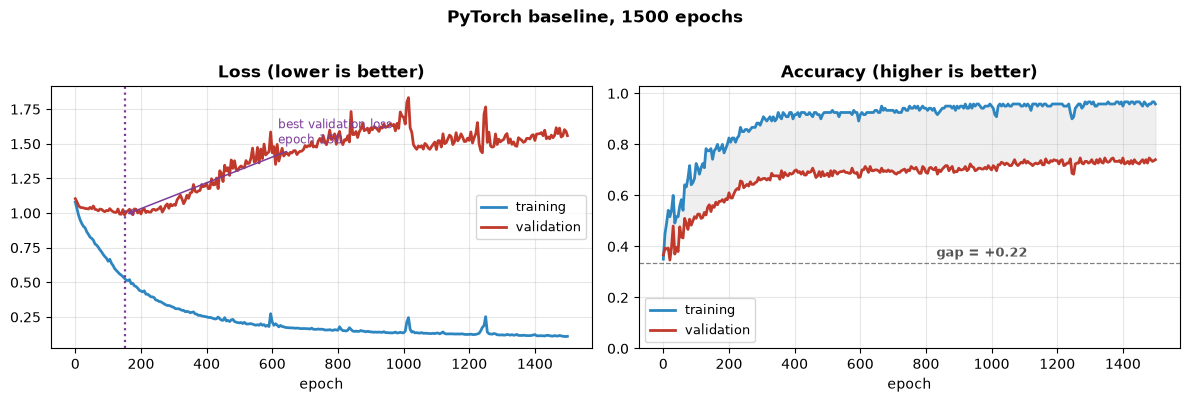

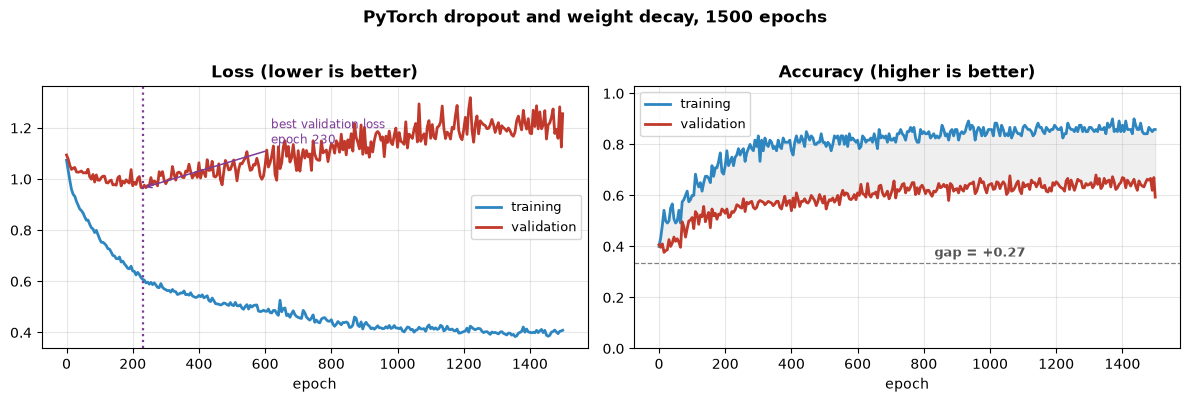

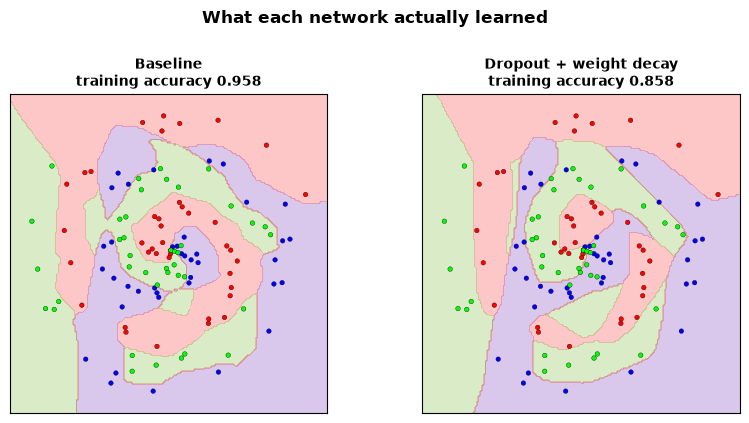

In [12]:
t0 = time.time()
baseline_model, baseline_history = run()
regularized_model, regularized_history = run(dropout=0.2, weight_decay=0.0001)
print(f'Two 1500-epoch runs completed in {time.time() - t0:.1f}s')
print(f"{'Model':<16} {'Train loss':>12} {'Train acc':>12} {'Val loss':>12} {'Val acc':>12}")
for name, trained_model in (('Baseline', baseline_model), ('Regularized', regularized_model)):
    tr_loss, tr_acc = evaluate(trained_model, Xtr, ytr)
    va_loss, va_acc = evaluate(trained_model, Xva, yva)
    print(f'{name:<16} {tr_loss:12.4f} {tr_acc:12.4f} {va_loss:12.4f} {va_acc:12.4f}')
draw_overfitting_curves(baseline_history, 'PyTorch baseline, 1500 epochs')
plt.show()
draw_overfitting_curves(regularized_history, 'PyTorch dropout and weight decay, 1500 epochs')
plt.show()

def predictor(trained_model):

    def predict(points):
        trained_model.eval()
        with torch.no_grad():
            return trained_model(torch.as_tensor(points, dtype=torch.float32)).argmax(dim=1).numpy()
    return predict
draw_decision_boundaries({'Baseline': predictor(baseline_model), 'Dropout + weight decay': predictor(regularized_model)}, X_train, y_train)
plt.show()


### Reading the results

Compare the printed validation losses and accuracies and inspect each training–validation gap. Falling training loss together with rising validation loss indicates overfitting. Regularization changes the learned fit and may reduce validation loss, but an improvement in accuracy is not guaranteed for every dataset or run. The validation set is used for comparison and never used in the gradient updates.


In [13]:
assert np.isfinite(difference) and difference < 1e-08
assert ytr.dtype == torch.long and yva.dtype == torch.long
for trained_model, history in ((baseline_model, baseline_history), (regularized_model, regularized_history)):
    assert sum((parameter.numel() for parameter in trained_model.parameters())) == 771
    assert len(history) == 301 and history[-1][0] == 1499
    assert np.isfinite(np.asarray(history)).all()
    assert all((0 <= row[2] <= 1 and 0 <= row[4] <= 1 for row in history))
    assert not trained_model.training
    with torch.no_grad():
        logits = trained_model(Xva)
        probabilities = logits.softmax(dim=1)
    assert torch.equal(logits.argmax(dim=1), probabilities.argmax(dim=1))
    assert torch.allclose(probabilities.sum(dim=1), torch.ones(len(Xva)), atol=1e-06)
print('All exercise and full-run verification checks passed.')


All exercise and full-run verification checks passed.


---

## What you did today

| Keras did it for you | You wrote it |
|---|---|
| `model.fit(...)` | `zero_grad` → forward → `backward` → `step` |
| batching and shuffling | a `DataLoader` (and, before that, the shuffle by hand) |
| training/inference switching | `model.train()` and `model.eval()` |
| `model.evaluate(...)` | `evaluate`, with `torch.no_grad()` |

### Which framework should you use?

Neither is better. Keras is faster to write and harder to break; PyTorch is more verbose and gets
out of your way. If you are fitting a standard model, `fit` is three lines and you should use it.
If you need a loop that does something unusual — two optimizers, a custom schedule, a loss that
depends on the epoch number, a GAN — you want the loop in your hands, and that is Lab 11's problem.

What matters is that neither framework surprised you today. Every line mapped onto something you
had already built yourself, which was the entire point of the first six weeks.

**End of notebook**